# EDA khách hàng bán buôn

Nhận xét và giải thích: [docs/nhan_xet_eda.md](docs/nhan_xet_eda.md).

Chạy bằng kernel Conda `Tracen`: Restart Kernel & Run All.

## 1. Thư viện và đường dẫn

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SPENDING = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
CONTEXT = ["Channel", "Region"]
EXPECTED = CONTEXT + SPENDING

# Tìm thư mục dự án từ thư mục chạy notebook hoặc các thư mục cha.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/wholesale_customers.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy data")
DATA_PATH = ROOT / "data/raw/wholesale_customers.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.unicode_minus": False})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


Python executable: /opt/homebrew/Caskroom/miniconda/base/envs/Tracen/bin/python
Nguồn dữ liệu: /Users/narutojaki/Customer-KNN/data/raw/wholesale_customers.csv


,Phiên bản
python,3.12.13
numpy,2.5.1
pandas,3.0.6
matplotlib,3.11.0
seaborn,0.13.2


## 2. Xem các dòng mẫu và cấu trúc dữ liệu

In [ ]:
df = pd.read_csv(DATA_PATH)
assert df.shape == (440, 8), f"Kích thước khác mong đợi: {df.shape}"
assert list(df.columns) == EXPECTED, f"Sai cấu trúc cột: {list(df.columns)}"
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in EXPECTED), "Có cột không phải số"

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
display(df.head(10))
display(quality)
print("Kích thước:", df.shape)
print("Số dòng trùng hoàn toàn (sau lần xuất hiện đầu):", int(df.duplicated().sum()))
print("Số hồ sơ chi tiêu trùng:", int(df.duplicated(subset=SPENDING).sum()))
assert not df.isna().any().any(), "Có giá trị thiếu; cần xem xét trước khi biến đổi"
assert np.isfinite(df.to_numpy(dtype=float)).all(), "Có giá trị vô hạn"
assert (df[SPENDING] >= 0).all().all(), "Có chi tiêu âm"
assert df["Channel"].isin([1, 2]).all(), "Mã Channel không hợp lệ"
assert df["Region"].isin([1, 2, 3]).all(), "Mã Region không hợp lệ"
print("Đạt các kiểm tra cấu trúc và giá trị.")

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
5,2,3,9413,8259,5126,666,1795,1451
6,2,3,12126,3199,6975,480,3140,545
7,2,3,7579,4956,9426,1669,3321,2566
8,1,3,5963,3648,6192,425,1716,750
9,2,3,6006,11093,18881,1159,7425,2098


,dtype,missing,unique,min,max
Channel,int64,0,2,1,2
Region,int64,0,3,1,3
Fresh,int64,0,433,3,112151
Milk,int64,0,421,55,73498
Grocery,int64,0,430,3,92780
Frozen,int64,0,426,25,60869
Detergents_Paper,int64,0,417,3,40827
Delicassen,int64,0,403,3,47943


Kích thước: (440, 8)
Số dòng trùng hoàn toàn (sau lần xuất hiện đầu): 0
Số hồ sơ chi tiêu trùng: 0
Đạt các kiểm tra cấu trúc và giá trị.


## 3. Thống kê và phân phối chi tiêu

,count,mean,std,min,25%,50%,75%,95%,99%,max,skewness
Fresh,440.000,"12,000.298","12,647.329",3.000,"3,127.750","8,504.000","16,933.750","36,818.500","56,082.610","112,151.000",2.561
Milk,440.000,"5,796.266","7,380.377",55.000,"1,533.000","3,627.000","7,190.250","16,843.400","37,610.060","73,498.000",4.054
Grocery,440.000,"7,951.277","9,503.163",3.000,"2,153.000","4,755.500","10,655.750","24,033.500","43,435.740","92,780.000",3.587
Frozen,440.000,"3,071.932","4,854.673",25.000,742.250,"1,526.000","3,554.250","9,930.750","17,964.820","60,869.000",5.908
Detergents_Paper,440.000,"2,881.493","4,767.854",3.000,256.750,816.500,"3,922.000","12,043.200","22,571.610","40,827.000",3.632
Delicassen,440.000,"1,524.870","2,820.106",3.000,408.250,965.500,"1,820.250","4,485.400","8,274.660","47,943.000",11.152


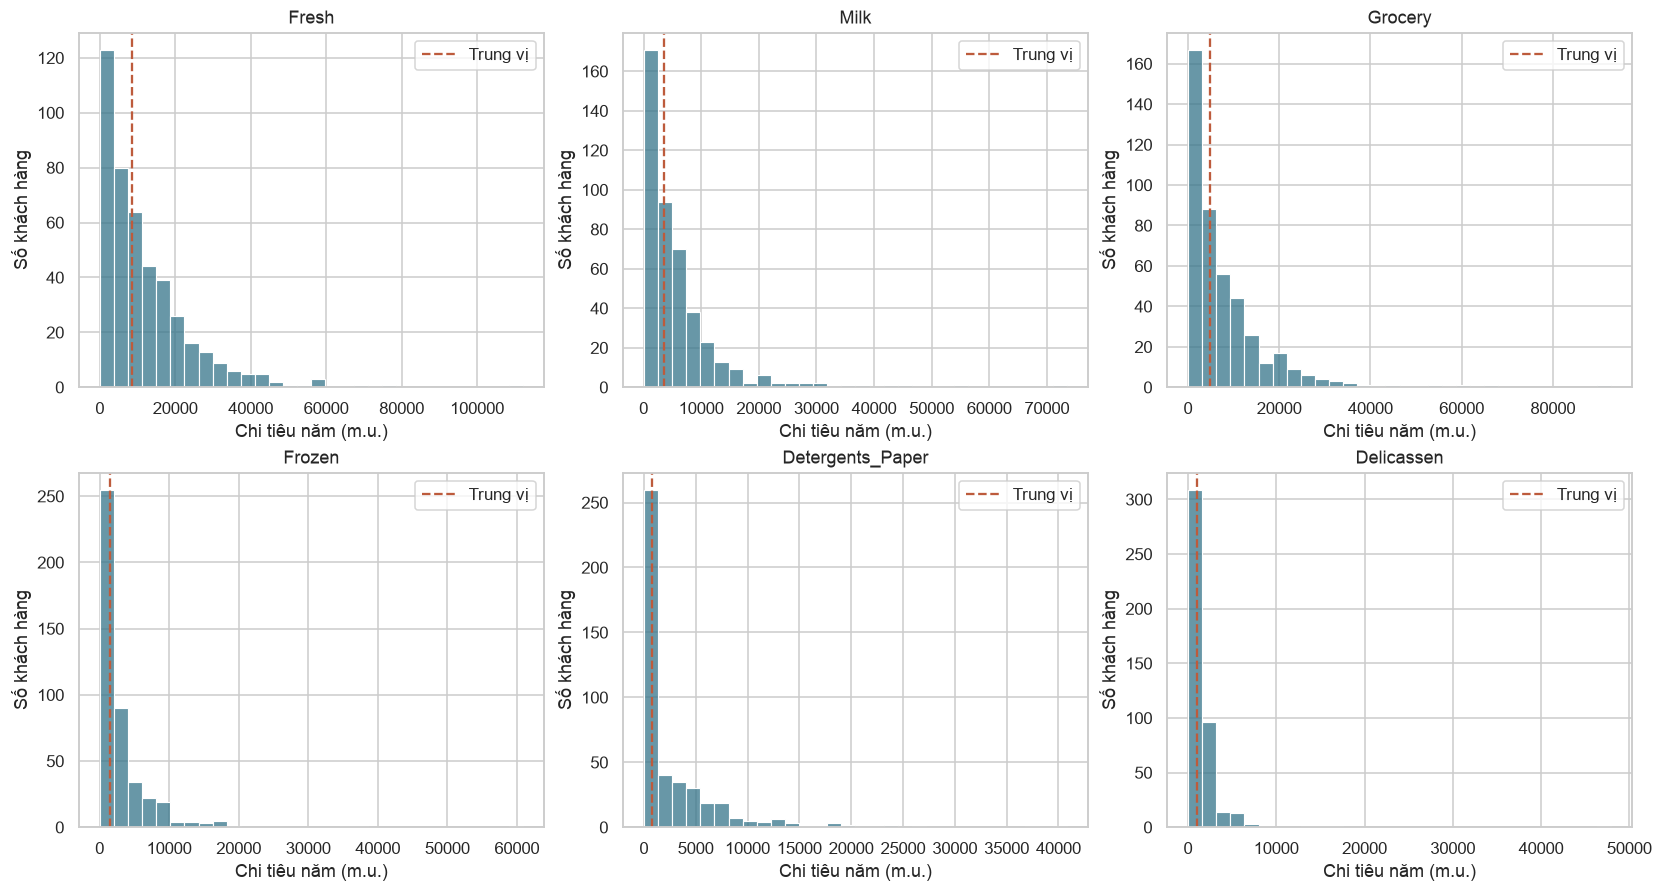

In [3]:
X_raw = df.loc[:, SPENDING].copy()
metadata = df.loc[:, CONTEXT].copy()
summary = X_raw.describe(percentiles=[.25, .5, .75, .95, .99]).T
summary["skewness"] = X_raw.skew()
display(summary)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for col, ax in zip(SPENDING, axes.flat):
    sns.histplot(X_raw[col], bins=30, ax=ax, color="#35758A")
    ax.axvline(X_raw[col].median(), color="#BD5B3C", linestyle="--", label="Trung vị")
    ax.set(title=col, xlabel="Chi tiêu năm (m.u.)", ylabel="Số khách hàng")
    ax.legend()
plt.show()

### 3.1 Phân tích độ lệch của từng biến

In [4]:
distribution_analysis = pd.DataFrame({
    "mean": X_raw.mean(),
    "median": X_raw.median(),
    "mean_to_median": X_raw.mean() / X_raw.median(),
    "p95": X_raw.quantile(0.95),
    "max": X_raw.max(),
    "skewness": X_raw.skew(),
})
display(distribution_analysis)


,mean,median,mean_to_median,p95,max,skewness
Fresh,"12,000.298","8,504.000",1.411,"36,818.500",112151,2.561
Milk,"5,796.266","3,627.000",1.598,"16,843.400",73498,4.054
Grocery,"7,951.277","4,755.500",1.672,"24,033.500",92780,3.587
Frozen,"3,071.932","1,526.000",2.013,"9,930.750",60869,5.908
Detergents_Paper,"2,881.493",816.500,3.529,"12,043.200",40827,3.632
Delicassen,"1,524.870",965.500,1.579,"4,485.400",47943,11.152


## 4. Boxplot và các điểm ngoại lệ tiềm năng

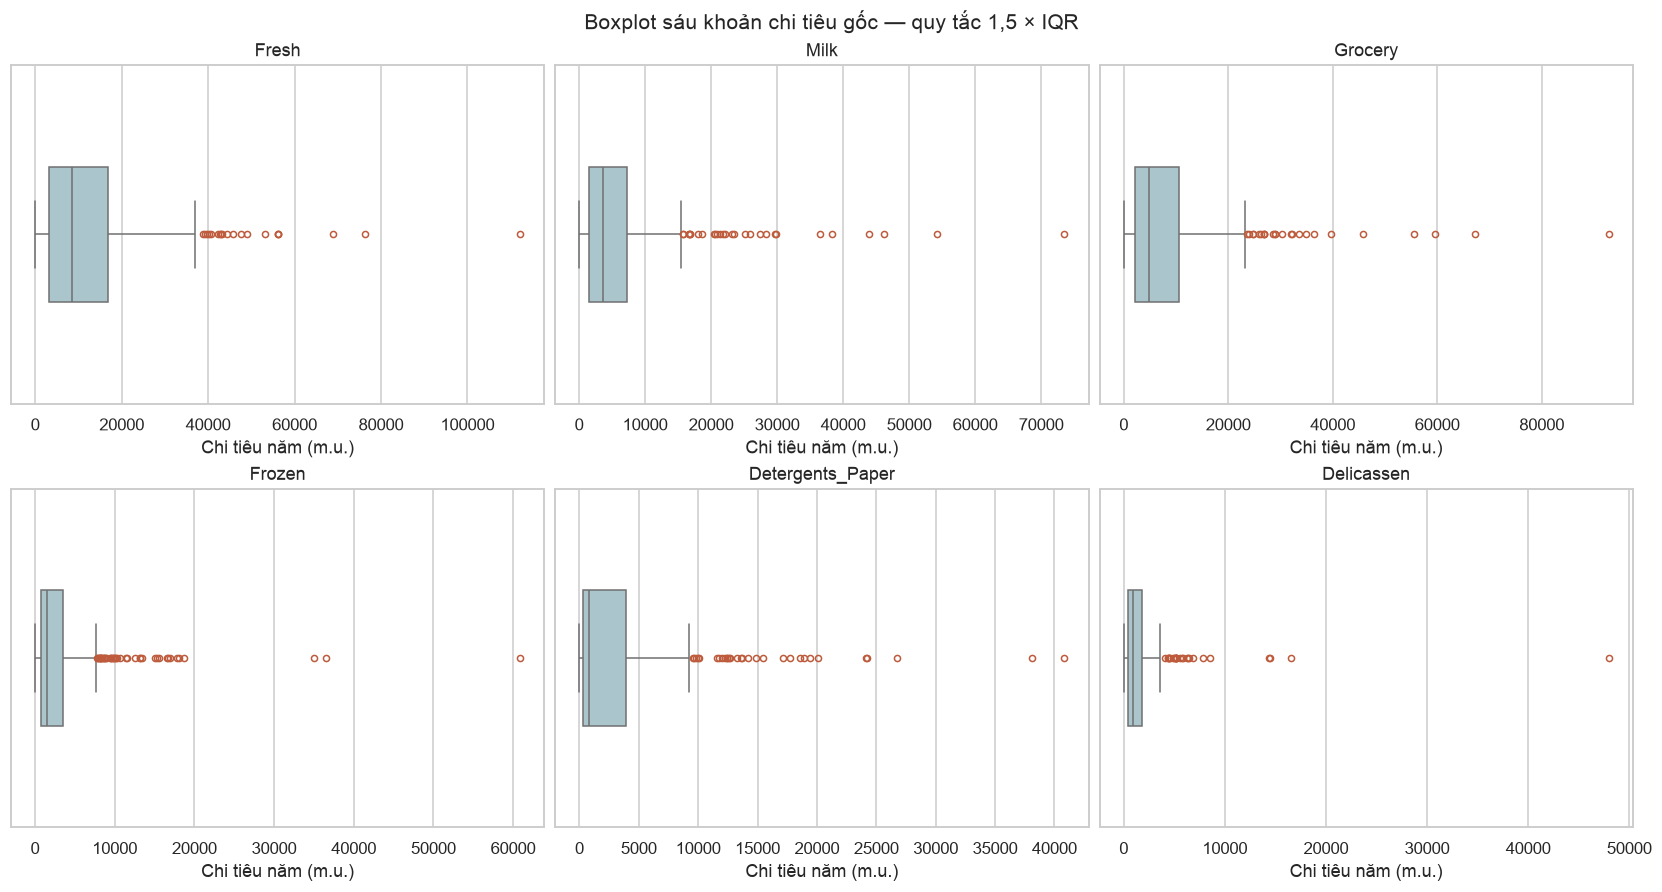

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for col, ax in zip(SPENDING, axes.flat):
    sns.boxplot(
        x=X_raw[col], ax=ax, whis=1.5, showfliers=True,
        color="#A5C8D1", width=0.4,
        flierprops={"marker": "o", "markersize": 4,
                    "markerfacecolor": "none", "markeredgecolor": "#BD5B3C"},
    )
    ax.set(title=col, xlabel="Chi tiêu năm (m.u.)", ylabel="")
fig.suptitle("Boxplot sáu khoản chi tiêu gốc — quy tắc 1,5 × IQR", fontsize=14)
plt.show()

### 4.1 Thống kê ngoại lệ theo quy tắc IQR

In [ ]:
q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
low_flags = X_raw.lt(lower_fence, axis="columns")
high_flags = X_raw.gt(upper_fence, axis="columns")
outlier_flags = low_flags | high_flags

outlier_analysis = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "below_count": low_flags.sum(), "above_count": high_flags.sum(),
    "flagged_count": outlier_flags.sum(),
    "flagged_pct": outlier_flags.mean() * 100,
})
display(outlier_analysis)
flag_count_per_customer = outlier_flags.sum(axis=1)
flagged_customers = int(flag_count_per_customer.gt(0).sum())
multi_flagged_customers = int(flag_count_per_customer.gt(1).sum())
print(f"Số khách bị gắn cờ ít nhất một biến: {flagged_customers}/{len(df)} ({flagged_customers / len(df):.2%})")
print(f"Số khách bị gắn cờ ở từ hai biến: {multi_flagged_customers}")
print(f"Tổng số cờ trên sáu cột: {int(outlier_flags.to_numpy().sum())}")

# Bảng hỗ trợ xem lại, không dùng làm đặc trưng đầu vào và không sửa df.
outlier_review = df.loc[flag_count_per_customer.gt(0)].copy()
outlier_review.index.name = "row_id"
outlier_review["flag_count"] = flag_count_per_customer.loc[outlier_review.index]
outlier_review["flagged_features"] = outlier_flags.loc[outlier_review.index].apply(
    lambda row: ", ".join(row.index[row]), axis=1
)
outlier_review = outlier_review.sort_values("flag_count", ascending=False, kind="stable")
print("10 dòng đầu của bảng xem lại, sắp xếp giảm dần:")
display(outlier_review.head(10))


,Q1,Q3,IQR,lower_fence,upper_fence,below_count,above_count,flagged_count,flagged_pct
Fresh,"3,127.750","16,933.750","13,806.000","-17,581.250","37,642.750",0,20,20,4.545
Milk,"1,533.000","7,190.250","5,657.250","-6,952.875","15,676.125",0,28,28,6.364
Grocery,"2,153.000","10,655.750","8,502.750","-10,601.125","23,409.875",0,24,24,5.455
Frozen,742.250,"3,554.250","2,812.000","-3,475.750","7,772.250",0,43,43,9.773
Detergents_Paper,256.750,"3,922.000","3,665.250","-5,241.125","9,419.875",0,30,30,6.818
Delicassen,408.250,"1,820.250","1,412.000","-1,709.750","3,938.250",0,27,27,6.136


Số khách bị gắn cờ ít nhất một biến: 108/440 (24.55%)
Số khách bị gắn cờ ở từ hai biến: 41
Tổng số cờ trên sáu cột: 172
10 dòng đầu của bảng xem lại, sắp theo số biến bị gắn cờ giảm dần:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,flag_count,flagged_features
row_id,,,,,,,,,,
47,2,3,44466,54259,55571,7782,24171,6465,6,"Fresh, Milk, Grocery, Frozen, Detergents_Paper..."
92,2,3,9198,27472,32034,3232,18906,5130,4,"Milk, Grocery, Detergents_Paper, Delicassen"
181,1,3,112151,29627,18148,16745,4948,8550,4,"Fresh, Milk, Frozen, Delicassen"
251,2,1,6134,23133,33586,6746,18594,5121,4,"Milk, Grocery, Detergents_Paper, Delicassen"
28,2,3,4113,20484,25957,1158,8604,5206,3,"Milk, Grocery, Delicassen"
49,2,3,4967,21412,28921,1798,13583,1163,3,"Milk, Grocery, Detergents_Paper"
56,2,3,4098,29892,26866,2616,17740,1340,3,"Milk, Grocery, Detergents_Paper"
61,2,3,35942,38369,59598,3254,26701,2017,3,"Milk, Grocery, Detergents_Paper"
65,2,3,85,20959,45828,36,24231,1423,3,"Milk, Grocery, Detergents_Paper"


## 5. Tương quan giữa các khoản chi tiêu

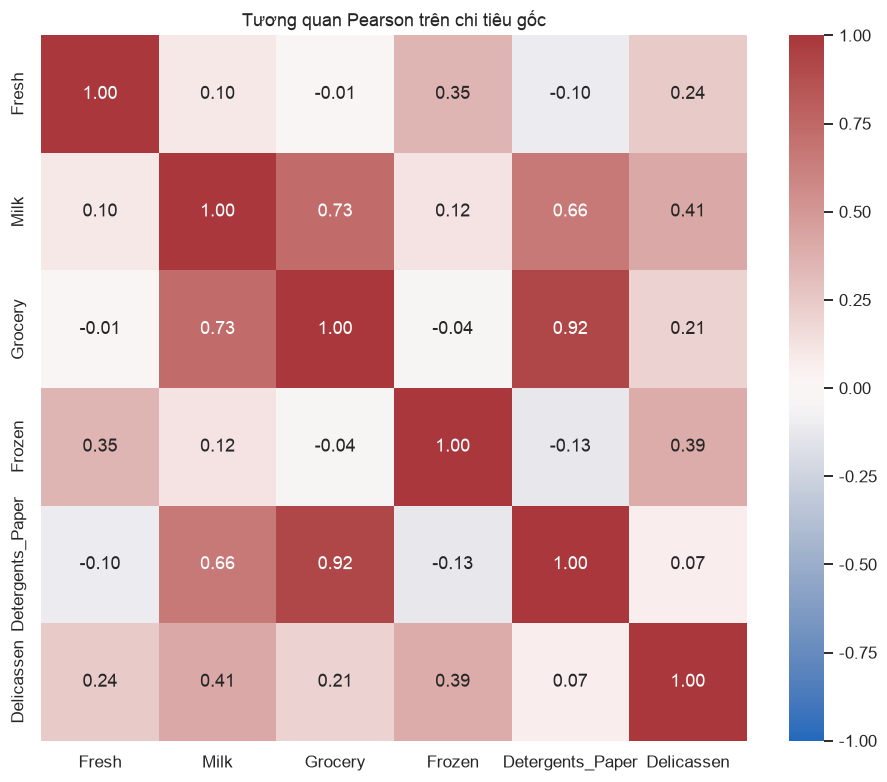

In [7]:
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
sns.heatmap(X_raw.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Tương quan Pearson trên chi tiêu gốc")
plt.show()

## 6. Channel và Region

In [8]:
channel_names = {1: "Horeca", 2: "Retail"}
region_names = {1: "Lisbon", 2: "Oporto", 3: "Other"}
for column, names in [("Channel", channel_names), ("Region", region_names)]:
    counts = df[column].value_counts().sort_index()
    table = counts.rename("Số khách hàng").to_frame()
    table.insert(0, "Ý nghĩa", table.index.map(names))
    table["Tỷ lệ (%)"] = counts / len(df) * 100
    print(column)
    display(table)

Channel


,Ý nghĩa,Số khách hàng,Tỷ lệ (%)
Channel,,,
1,Horeca,298,67.727
2,Retail,142,32.273


Region


,Ý nghĩa,Số khách hàng,Tỷ lệ (%)
Region,,,
1,Lisbon,77,17.500
2,Oporto,47,10.682
3,Other,316,71.818


## 7. Cấu trúc dữ liệu trong chương trình

In [ ]:
structure_overview = pd.DataFrame([
    {"variable": name, "type": type(value).__name__, "shape": str(value.shape)}
    for name, value in [
        ("df", df), ("X_raw", X_raw), ("metadata", metadata),
        ("summary", summary), ("distribution_analysis", distribution_analysis),
        ("outlier_flags", outlier_flags), ("flag_count_per_customer", flag_count_per_customer),
        ("outlier_analysis", outlier_analysis), ("outlier_review", outlier_review),
    ]
])
display(structure_overview)
display(pd.DataFrame({"dtype_X_raw": X_raw.dtypes.astype(str),
                      "dtype_outlier_flags": outlier_flags.dtypes.astype(str)}))

assert X_raw.shape == (len(df), len(SPENDING))
assert metadata.shape == (len(df), len(CONTEXT))
assert X_raw.index.equals(metadata.index)
assert not set(CONTEXT).intersection(X_raw.columns)
assert outlier_flags.shape == X_raw.shape
assert all(dtype == bool for dtype in outlier_flags.dtypes)
assert int(outlier_flags.any(axis=1).sum()) == len(outlier_review)
assert int(flag_count_per_customer.sum()) == int(outlier_analysis["flagged_count"].sum())
assert X_raw.equals(df.loc[:, SPENDING])
assert metadata.equals(df.loc[:, CONTEXT])


,variable,type,shape
0,df,DataFrame,"(440, 8)"
1,X_raw,DataFrame,"(440, 6)"
2,metadata,DataFrame,"(440, 2)"
3,summary,DataFrame,"(6, 11)"
4,distribution_analysis,DataFrame,"(6, 6)"
5,outlier_flags,DataFrame,"(440, 6)"
6,flag_count_per_customer,Series,"(440,)"
7,outlier_analysis,DataFrame,"(6, 9)"
8,outlier_review,DataFrame,"(108, 10)"


,dtype_X_raw,dtype_outlier_flags
Fresh,int64,bool
Milk,int64,bool
Grocery,int64,bool
Frozen,int64,bool
Detergents_Paper,int64,bool
Delicassen,int64,bool


Đã kiểm tra kích thước, chỉ số dòng và tính nhất quán; dữ liệu gốc vẫn được giữ nguyên.
